In [1]:

from pathlib import Path
import warnings
import json
import time

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

warnings.filterwarnings("ignore")

# Locate the project root automatically
PROJECT_ROOT = None

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "data").exists() and (path / "results").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Make sure this notebook is inside the project directory."
    )

print("Project root:", PROJECT_ROOT)


Project root: /Users/mustafaahmed/Documents/Security Code Review Analysis


In [2]:

DATA_PATH = (
    PROJECT_ROOT
    / "data/gerrit/couchbase_java_client/processed/"
    / "gerrit_modeling_intermediate_expansion.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results/machine_learning/gerrit_expanded"
)

MODEL_DIR = OUTPUT_DIR / "models"
METRICS_DIR = OUTPUT_DIR / "metrics"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"

for directory in [MODEL_DIR, METRICS_DIR, PREDICTIONS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")


Dataset: /Users/mustafaahmed/Documents/Security Code Review Analysis/data/gerrit/couchbase_java_client/processed/gerrit_modeling_intermediate_expansion.csv
Output directory: /Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded


In [3]:

df = pd.read_csv(DATA_PATH)

print("Expanded Gerrit dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())


Expanded Gerrit dataset loaded successfully.
Dataset shape: (1774, 18)


,review_number,revision_number,commit_id,gerrit_ref,status,previous_revision,changed_files,insertions,deletions,git_fetch_success,comparison_success,code_diff,review_messages,security_label,original_security_label,security_label_binary,label_source,label_evidence_categories
0,12027,1,634fb3ea0b12e60b8d8b27d9aa3f36d5f394d83e,refs/changes/27/12027/1,ABANDONED,parent,2.0,8.0,2.0,True,True,diff --git a/src/test/java/net/spy/memcached/M...,"[{""message_id"": ""6015f49d48eb9e0ca5c9800f5fc37...",1,1,0,Original Gerrit label,NaN
1,12050,1,dd6454bd6574a9337528281df912f51a9fda52ad,refs/changes/50/12050/1,MERGED,parent,51.0,8348.0,12.0,True,True,diff --git a/build.xml b/build.xml\nindex 860a...,[],1,1,1,Intermediate security weak label,"authentication, authorization_and_access_contr..."
2,12050,2,8c338944a8c4e5e068db7009c41be5cbcb8b72f1,refs/changes/50/12050/2,MERGED,1,50.0,0.0,8281.0,True,True,diff --git a/src/main/java/net/spy/memcached/M...,"[{""message_id"": ""5030f5f9921306a662d8dc1ad3517...",1,1,0,Intermediate security weak label,NaN
3,12050,3,eddbfeac3b56721994ab0bdc7a63ded3aec6bb1a,refs/changes/50/12050/3,MERGED,2,2.0,3.0,5.0,True,True,diff --git a/src/main/java/com/couchbase/clien...,"[{""message_id"": ""5eac3df10dc8f15d5f884220f87ac...",1,1,0,Original Gerrit label,NaN
4,12050,4,ced15bea74bce3e242865edd18d5cb1370d2eecb,refs/changes/50/12050/4,MERGED,3,20.0,75.0,74.0,True,True,diff --git a/src/main/java/com/couchbase/clien...,"[{""message_id"": ""65f6cae68def4634be863be263c64...",1,1,0,Original Gerrit label,NaN


In [4]:

TARGET = "security_label_binary"
TEXT_COLUMN = "code_diff"
GROUP_COLUMN = "review_number"

required_columns = [
    TARGET,
    TEXT_COLUMN,
    GROUP_COLUMN
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns are present.")

print("\nTarget values:")
print(df[TARGET].value_counts(dropna=False).sort_index())

print("\nTarget data types:")
print(df[TARGET].dtype)

print("\nMissing values:")
print(df[required_columns].isnull().sum())

if df[TARGET].isnull().any():
    raise ValueError("Target contains missing values.")

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError(
        "Target must contain only binary values 0 and 1."
    )

print("\nLabel mapping:")
print("0 = Not security-related")
print("1 = Security-related")


Required columns are present.

Target values:
security_label_binary
0    1382
1     392
Name: count, dtype: int64

Target data types:
int64

Missing values:
security_label_binary    0
code_diff                0
review_number            0
dtype: int64

Label mapping:
0 = Not security-related
1 = Security-related


In [5]:

df_model = df.copy()

# Remove rows without usable code diffs or review identifiers
df_model[TEXT_COLUMN] = (
    df_model[TEXT_COLUMN]
    .fillna("")
    .astype(str)
)

df_model = df_model[
    (df_model[TEXT_COLUMN].str.strip() != "")
    & df_model[GROUP_COLUMN].notna()
].copy()

df_model[TARGET] = df_model[TARGET].astype(int)

df_model = df_model.reset_index(drop=True)

X = df_model[TEXT_COLUMN]
y = df_model[TARGET]
groups = df_model[GROUP_COLUMN]

print("Modelling dataset prepared.")
print("Total revisions:", len(df_model))
print("Unique review groups:", groups.nunique())

print("\nClass distribution:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={
        0: "Not security-related",
        1: "Security-related"
    })
    .to_frame("Count")
)

print("\nClass percentages:")
display(
    (y.value_counts(normalize=True) * 100)
    .sort_index()
    .rename(index={
        0: "Not security-related",
        1: "Security-related"
    })
    .round(2)
    .to_frame("Percentage")
)


Modelling dataset prepared.
Total revisions: 1774
Unique review groups: 808

Class distribution:


,Count
security_label_binary,
Not security-related,1382
Security-related,392



Class percentages:


,Percentage
security_label_binary,
Not security-related,77.9
Security-related,22.1


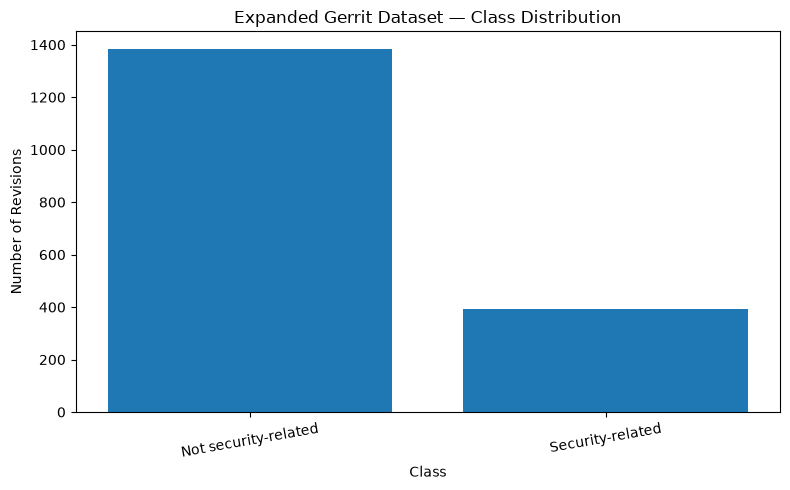

In [7]:
import matplotlib.pyplot as plt

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Not security-related", "Security-related"],
    [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
)

plt.title("Expanded Gerrit Dataset — Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Revisions")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


In [8]:

N_SPLITS = 5
RANDOM_STATE = 42

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation configured.")
print("Number of folds:", N_SPLITS)
print("Unique review groups:", groups.nunique())

fold_information = []

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    train_groups = set(groups.iloc[train_idx])
    valid_groups = set(groups.iloc[valid_idx])

    overlap = train_groups.intersection(valid_groups)

    fold_information.append({
        "Fold": fold_number,
        "Training Rows": len(train_idx),
        "Validation Rows": len(valid_idx),
        "Training Positives": int(y.iloc[train_idx].sum()),
        "Validation Positives": int(y.iloc[valid_idx].sum()),
        "Training Reviews": len(train_groups),
        "Validation Reviews": len(valid_groups),
        "Overlapping Reviews": len(overlap)
    })

fold_df = pd.DataFrame(fold_information)

display(fold_df)

if (fold_df["Overlapping Reviews"] > 0).any():
    raise ValueError(
        "Review groups overlap between training and validation folds."
    )

print("All folds have zero overlapping review groups.")


Cross-validation configured.
Number of folds: 5
Unique review groups: 808


,Fold,Training Rows,Validation Rows,Training Positives,Validation Positives,Training Reviews,Validation Reviews,Overlapping Reviews
0,1,1418,356,313,79,652,156,0
1,2,1420,354,314,78,636,172,0
2,3,1420,354,314,78,648,160,0
3,4,1419,355,313,79,650,158,0
4,5,1419,355,314,78,646,162,0


All folds have zero overlapping review groups.


In [9]:

TFIDF_SETTINGS = {
    "max_features": 5000,
    "ngram_range": (1, 2),
    "min_df": 2,
    "sublinear_tf": True,
    "stop_words": "english"
}

EXPERIMENTS = [
    {
        "name": "TF-IDF + Random Oversampling",
        "strategy": "Random oversampling"
    },
    {
        "name": "TF-IDF + Class Weighting",
        "strategy": "Class weighting"
    }
]

print("TF-IDF settings:")
print(TFIDF_SETTINGS)

print("\nExperiments:")
for experiment in EXPERIMENTS:
    print("-", experiment["name"])


TF-IDF settings:
{'max_features': 5000, 'ngram_range': (1, 2), 'min_df': 2, 'sublinear_tf': True, 'stop_words': 'english'}

Experiments:
- TF-IDF + Random Oversampling
- TF-IDF + Class Weighting


In [10]:

def evaluate_model(y_true, predictions, scores):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),
        "PR_AUC": average_precision_score(
            y_true, scores
        )
    }


print("Evaluation function created.")


Evaluation function created.


In [11]:

results = []

for experiment in EXPERIMENTS:

    print("\n" + "=" * 70)
    print("Experiment:", experiment["name"])
    print("=" * 70)

    for fold_number, (train_idx, valid_idx) in enumerate(
        cv.split(X, y, groups),
        start=1
    ):

        print(f"Processing fold {fold_number}/{N_SPLITS}...")

        X_train = X.iloc[train_idx]
        X_valid = X.iloc[valid_idx]

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        # Fit TF-IDF using training data only
        vectorizer = TfidfVectorizer(**TFIDF_SETTINGS)

        X_train_tfidf = vectorizer.fit_transform(X_train)
        X_valid_tfidf = vectorizer.transform(X_valid)

        # Configure model and imbalance strategy
        if experiment["strategy"] == "Random oversampling":

            sampler = RandomOverSampler(
                random_state=RANDOM_STATE
            )

            X_fit, y_fit = sampler.fit_resample(
                X_train_tfidf,
                y_train
            )

            model = LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )

        elif experiment["strategy"] == "Class weighting":

            X_fit = X_train_tfidf
            y_fit = y_train

            model = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )

        else:
            raise ValueError("Unknown imbalance strategy.")

        start_time = time.time()

        model.fit(X_fit, y_fit)

        training_time = time.time() - start_time

        predictions = model.predict(X_valid_tfidf)
        scores = model.predict_proba(X_valid_tfidf)[:, 1]

        metrics = evaluate_model(
            y_valid,
            predictions,
            scores
        )

        results.append({
            "Fold": fold_number,
            "Model": experiment["name"],
            **metrics,
            "Training Time": training_time,
            "Training Rows": len(train_idx),
            "Validation Rows": len(valid_idx)
        })

print("\nAll experiments completed.")



Experiment: TF-IDF + Random Oversampling
Processing fold 1/5...
Processing fold 2/5...
Processing fold 3/5...
Processing fold 4/5...
Processing fold 5/5...

Experiment: TF-IDF + Class Weighting
Processing fold 1/5...
Processing fold 2/5...
Processing fold 3/5...
Processing fold 4/5...
Processing fold 5/5...

All experiments completed.


In [12]:

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Model", "Fold"]
    ).round(4)
)


,Fold,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,PR_AUC,Training Time,Training Rows,Validation Rows
5,1,TF-IDF + Class Weighting,0.8820,0.8518,0.7079,0.7975,0.7500,0.8442,0.0154,1418,356
6,2,TF-IDF + Class Weighting,0.8418,0.8250,0.6078,0.7949,0.6889,0.7943,0.0148,1420,354
7,3,TF-IDF + Class Weighting,0.8588,0.8588,0.6321,0.8590,0.7283,0.8675,0.0123,1420,354
8,4,TF-IDF + Class Weighting,0.8704,0.8715,0.6571,0.8734,0.7500,0.9039,0.0191,1419,355
9,5,TF-IDF + Class Weighting,0.8901,0.8651,0.7191,0.8205,0.7665,0.8444,0.0152,1419,355
0,1,TF-IDF + Random Oversampling,0.8876,0.8464,0.7349,0.7722,0.7531,0.8496,0.1594,1418,356
1,2,TF-IDF + Random Oversampling,0.8701,0.8477,0.6702,0.8077,0.7326,0.8060,0.0257,1420,354
2,3,TF-IDF + Random Oversampling,0.8870,0.8724,0.7021,0.8462,0.7674,0.8719,0.0230,1420,354
3,4,TF-IDF + Random Oversampling,0.8873,0.8959,0.6857,0.9114,0.7826,0.9238,0.0238,1419,355
4,5,TF-IDF + Random Oversampling,0.8958,0.8687,0.7356,0.8205,0.7758,0.8566,0.0280,1419,355


In [13]:

metric_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "PR_AUC",
    "Training Time"
]

summary_df = (
    results_df
    .groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.sort_values(
    "PR_AUC_mean",
    ascending=False
)

display(summary_df.round(4))


,Accuracy_mean,Accuracy_std,Balanced Accuracy_mean,Balanced Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,PR_AUC_mean,PR_AUC_std,Training Time_mean,Training Time_std
Model,,,,,,,,,,,,,,
TF-IDF + Random Oversampling,0.8856,0.0094,0.8662,0.0204,0.7057,0.0293,0.8316,0.0520,0.7623,0.0199,0.8616,0.0425,0.0520,0.0601
TF-IDF + Class Weighting,0.8686,0.0191,0.8544,0.0180,0.6648,0.0479,0.8290,0.0357,0.7367,0.0300,0.8509,0.0399,0.0154,0.0025


In [14]:

best_model_name = summary_df.index[0]

best_model = summary_df.iloc[0]

print("=" * 65)
print("BEST EXPANDED GERRIT MODEL")
print("=" * 65)

print("Model:", best_model_name)

print(f"Mean PR-AUC: {best_model['PR_AUC_mean']:.4f}")
print(f"Mean F1: {best_model['F1_mean']:.4f}")
print(f"Mean Precision: {best_model['Precision_mean']:.4f}")
print(f"Mean Recall: {best_model['Recall_mean']:.4f}")
print(
    f"Mean Balanced Accuracy: "
    f"{best_model['Balanced Accuracy_mean']:.4f}"
)


BEST EXPANDED GERRIT MODEL
Model: TF-IDF + Random Oversampling
Mean PR-AUC: 0.8616
Mean F1: 0.7623
Mean Precision: 0.7057
Mean Recall: 0.8316
Mean Balanced Accuracy: 0.8662


In [15]:

best_fold_results = results_df[
    results_df["Model"] == best_model_name
].copy()

best_fold_results = best_fold_results.sort_values("Fold")

display(
    best_fold_results[
        [
            "Fold",
            "Precision",
            "Recall",
            "F1",
            "PR_AUC",
            "Balanced Accuracy"
        ]
    ].round(4)
)


,Fold,Precision,Recall,F1,PR_AUC,Balanced Accuracy
0,1,0.7349,0.7722,0.7531,0.8496,0.8464
1,2,0.6702,0.8077,0.7326,0.8060,0.8477
2,3,0.7021,0.8462,0.7674,0.8719,0.8724
3,4,0.6857,0.9114,0.7826,0.9238,0.8959
4,5,0.7356,0.8205,0.7758,0.8566,0.8687


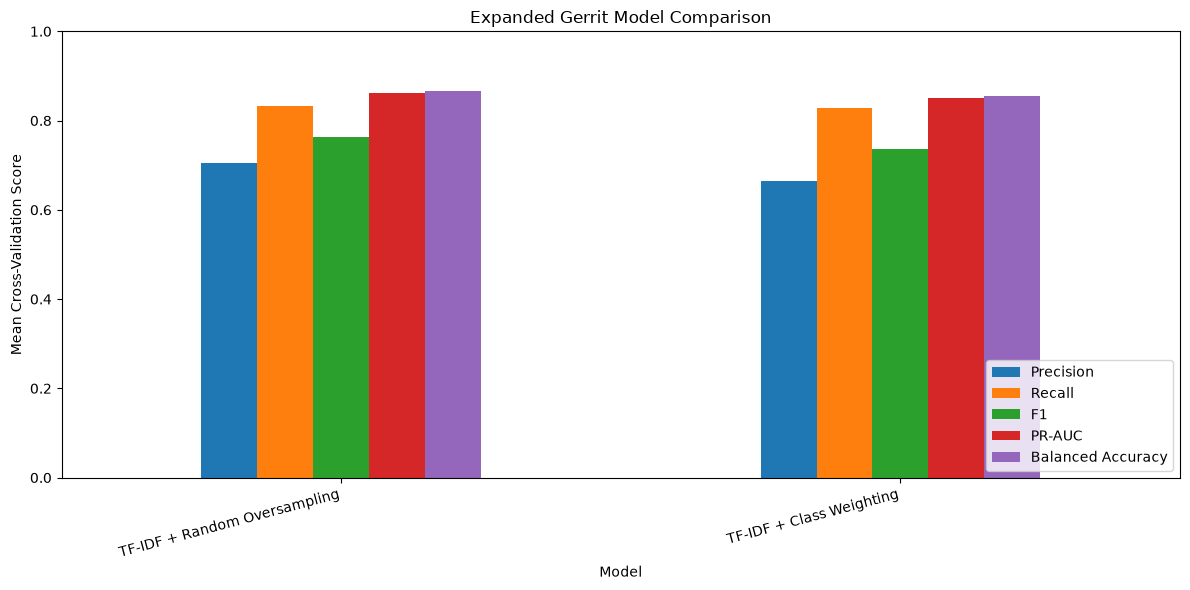

In [16]:

plot_metrics = [
    "Precision_mean",
    "Recall_mean",
    "F1_mean",
    "PR_AUC_mean",
    "Balanced Accuracy_mean"
]

plot_df = summary_df[plot_metrics].copy()

plot_df.columns = [
    "Precision",
    "Recall",
    "F1",
    "PR-AUC",
    "Balanced Accuracy"
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Expanded Gerrit Model Comparison")
ax.set_ylabel("Mean Cross-Validation Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [17]:

oof_predictions = np.zeros(len(df_model), dtype=int)
oof_scores = np.zeros(len(df_model), dtype=float)
oof_fold_numbers = np.zeros(len(df_model), dtype=int)

best_strategy = next(
    experiment["strategy"]
    for experiment in EXPERIMENTS
    if experiment["name"] == best_model_name
)

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    print(f"Generating out-of-fold predictions: fold {fold_number}")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]

    vectorizer = TfidfVectorizer(**TFIDF_SETTINGS)

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_valid_tfidf = vectorizer.transform(X_valid)

    if best_strategy == "Random oversampling":

        sampler = RandomOverSampler(
            random_state=RANDOM_STATE
        )

        X_fit, y_fit = sampler.fit_resample(
            X_train_tfidf,
            y_train
        )

        model = LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )

    else:

        X_fit = X_train_tfidf
        y_fit = y_train

        model = LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )

    model.fit(X_fit, y_fit)

    oof_predictions[valid_idx] = model.predict(X_valid_tfidf)

    oof_scores[valid_idx] = (
        model.predict_proba(X_valid_tfidf)[:, 1]
    )

    oof_fold_numbers[valid_idx] = fold_number

print("Out-of-fold predictions completed.")


Generating out-of-fold predictions: fold 1
Generating out-of-fold predictions: fold 2
Generating out-of-fold predictions: fold 3
Generating out-of-fold predictions: fold 4
Generating out-of-fold predictions: fold 5
Out-of-fold predictions completed.


In [18]:

oof_metrics = evaluate_model(
    y,
    oof_predictions,
    oof_scores
)

print("=" * 60)
print("POOLED OUT-OF-FOLD PERFORMANCE")
print("=" * 60)

for metric, value in oof_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y,
        oof_predictions,
        target_names=[
            "Not security-related",
            "Security-related"
        ],
        zero_division=0
    )
)

print("\nConfusion matrix:")

cm = confusion_matrix(y, oof_predictions)

display(
    pd.DataFrame(
        cm,
        index=["Actual Not Security", "Actual Security"],
        columns=["Predicted Not Security", "Predicted Security"]
    )
)


POOLED OUT-OF-FOLD PERFORMANCE
Accuracy: 0.8856
Balanced Accuracy: 0.8663
Precision: 0.7041
Recall: 0.8316
F1: 0.7626
PR_AUC: 0.8570

Classification report:
                      precision    recall  f1-score   support

Not security-related       0.95      0.90      0.92      1382
    Security-related       0.70      0.83      0.76       392

            accuracy                           0.89      1774
           macro avg       0.83      0.87      0.84      1774
        weighted avg       0.90      0.89      0.89      1774


Confusion matrix:


,Predicted Not Security,Predicted Security
Actual Not Security,1245,137
Actual Security,66,326


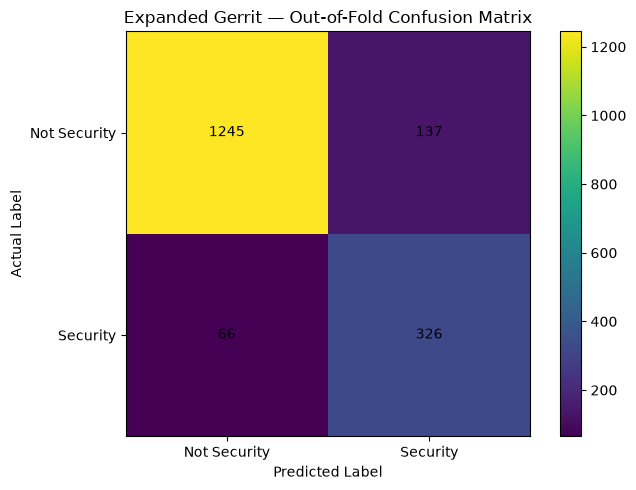

In [19]:

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Expanded Gerrit — Out-of-Fold Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Not Security", "Security"]
)

plt.yticks(
    [0, 1],
    ["Not Security", "Security"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()


In [20]:

error_df = df_model.copy()

error_df["actual_label"] = y.values
error_df["predicted_label"] = oof_predictions
error_df["security_score"] = oof_scores
error_df["fold"] = oof_fold_numbers

error_df["prediction_result"] = np.select(
    [
        (error_df["actual_label"] == 1)
        & (error_df["predicted_label"] == 1),

        (error_df["actual_label"] == 0)
        & (error_df["predicted_label"] == 0),

        (error_df["actual_label"] == 0)
        & (error_df["predicted_label"] == 1),

        (error_df["actual_label"] == 1)
        & (error_df["predicted_label"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

print("Prediction result distribution:")

display(
    error_df["prediction_result"]
    .value_counts()
    .to_frame("Count")
)


Prediction result distribution:


,Count
prediction_result,
True Negative,1245
True Positive,326
False Positive,137
False Negative,66


In [21]:

false_positives = error_df[
    error_df["prediction_result"] == "False Positive"
].copy()

false_positives = false_positives.sort_values(
    "security_score",
    ascending=False
)

print("False positives:", len(false_positives))

display(
    false_positives[
        [
            "review_number",
            "revision_number",
            "security_score",
            "code_diff"
        ]
    ].head(10)
)


False positives: 137


,review_number,revision_number,security_score,code_diff
2,12050,2,0.890364,diff --git a/src/main/java/net/spy/memcached/M...
610,40694,1,0.889058,diff --git a/src/integration/java/com/couchbas...
994,50385,1,0.873961,diff --git a/src/main/java/com/couchbase/clien...
746,44015,5,0.858720,diff --git a/src/integration/java/com/couchbas...
730,43556,1,0.845582,diff --git a/src/main/java/com/couchbase/clien...
1736,83081,1,0.841337,diff --git a/src/main/java/com/couchbase/clien...
758,44520,1,0.832737,diff --git a/src/integration/java/com/couchbas...
474,32589,10,0.826552,diff --git a/src/main/java/com/couchbase/clien...
687,42155,1,0.808560,diff --git a/src/main/java/com/couchbase/clien...
939,49377,1,0.806156,diff --git a/src/integration/java/com/couchbas...


In [22]:

false_negatives = error_df[
    error_df["prediction_result"] == "False Negative"
].copy()

false_negatives = false_negatives.sort_values(
    "security_score",
    ascending=True
)

print("False negatives:", len(false_negatives))

display(
    false_negatives[
        [
            "review_number",
            "revision_number",
            "security_score",
            "code_diff"
        ]
    ].head(10)
)


False negatives: 66


,review_number,revision_number,security_score,code_diff
287,27790,2,0.023416,diff --git a/src/main/java/com/couchbase/clien...
1468,67630,5,0.032119,diff --git a/pom.xml b/pom.xml\nindex 7cc36c68...
475,32589,11,0.040042,diff --git a/src/main/java/com/couchbase/clien...
840,45796,1,0.047452,diff --git a/README.md b/README.md\nindex 1b98...
1583,73513,2,0.051728,diff --git a/src/main/java/com/couchbase/clien...
1758,84365,1,0.052851,diff --git a/src/main/java/com/couchbase/clien...
484,32994,3,0.056376,diff --git a/src/main/java/com/couchbase/clien...
844,45860,3,0.073616,diff --git a/src/main/java/com/couchbase/clien...
1376,63854,1,0.079994,diff --git a/src/main/java/com/couchbase/clien...
464,32425,3,0.080756,diff --git a/src/main/java/com/couchbase/clien...


In [23]:

false_positives.to_csv(
    PREDICTIONS_DIR / "expanded_gerrit_false_positives.csv",
    index=False
)

false_negatives.to_csv(
    PREDICTIONS_DIR / "expanded_gerrit_false_negatives.csv",
    index=False
)

error_df.to_csv(
    PREDICTIONS_DIR / "expanded_gerrit_oof_predictions.csv",
    index=False
)

print("Error analysis files saved.")


Error analysis files saved.


In [24]:

final_vectorizer = TfidfVectorizer(**TFIDF_SETTINGS)

X_full_tfidf = final_vectorizer.fit_transform(X)

if best_strategy == "Random oversampling":

    final_sampler = RandomOverSampler(
        random_state=RANDOM_STATE
    )

    X_final_fit, y_final_fit = final_sampler.fit_resample(
        X_full_tfidf,
        y
    )

    final_model = LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )

else:

    X_final_fit = X_full_tfidf
    y_final_fit = y

    final_model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )

final_model.fit(X_final_fit, y_final_fit)

print("Final deployment model trained.")
print("Training rows:", len(X))
print("Training features:", X_full_tfidf.shape[1])
print("Selected strategy:", best_strategy)


Final deployment model trained.
Training rows: 1774
Training features: 5000
Selected strategy: Random oversampling


In [25]:

final_model_bundle = {
    "vectorizer": final_vectorizer,
    "model": final_model,
    "text_column": TEXT_COLUMN,
    "positive_class": 1,
    "positive_class_description": "Security-related",
    "label_mapping": {
        0: "Not security-related",
        1: "Security-related"
    },
    "model_name": best_model_name,
    "dataset": "gerrit_modeling_intermediate_expansion.csv",
    "tfidf_settings": TFIDF_SETTINGS,
    "cross_validation": {
        "method": "StratifiedGroupKFold",
        "n_splits": N_SPLITS,
        "group_column": GROUP_COLUMN,
        "random_state": RANDOM_STATE
    }
}

MODEL_PATH = (
    MODEL_DIR / "gerrit_expanded_tfidf_logistic_regression.joblib"
)

joblib.dump(final_model_bundle, MODEL_PATH)

print("Final model saved:")
print(MODEL_PATH)


Final model saved:
/Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded/models/gerrit_expanded_tfidf_logistic_regression.joblib


In [26]:

results_df.to_csv(
    METRICS_DIR / "expanded_gerrit_fold_results.csv",
    index=False
)

summary_df.to_csv(
    METRICS_DIR / "expanded_gerrit_model_comparison.csv"
)

pd.DataFrame(
    [oof_metrics]
).to_csv(
    METRICS_DIR / "expanded_gerrit_oof_metrics.csv",
    index=False
)

with open(
    METRICS_DIR / "expanded_gerrit_experiment_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        {
            "dataset": str(DATA_PATH),
            "total_revisions": int(len(df_model)),
            "unique_reviews": int(groups.nunique()),
            "not_security_related": int((y == 0).sum()),
            "security_related": int((y == 1).sum()),
            "best_model": best_model_name,
            "best_strategy": best_strategy,
            "cross_validation": "5-fold Stratified Group Cross-Validation",
            "group_column": GROUP_COLUMN,
            "pooled_oof_metrics": {
                key: float(value)
                for key, value in oof_metrics.items()
            }
        },
        file,
        indent=4
    )

print("Evaluation outputs saved successfully.")


Evaluation outputs saved successfully.


In [27]:

loaded_bundle = joblib.load(MODEL_PATH)

test_diff = """
+ public boolean validateUser(String username, String password) {
+     return authenticationService.authenticate(username, password);
+ }
"""

test_vector = loaded_bundle["vectorizer"].transform([test_diff])

test_prediction = loaded_bundle["model"].predict(test_vector)[0]
test_score = loaded_bundle["model"].predict_proba(test_vector)[0, 1]

print("Model verification successful.")
print("Prediction:", (
    "Security-related"
    if test_prediction == 1
    else "Not security-related"
))
print(f"Security score: {test_score:.4f}")


Model verification successful.
Prediction: Security-related
Security score: 0.8362


In [28]:

print("=" * 70)
print("EXPANDED GERRIT MODEL TRAINING — FINAL SUMMARY")
print("=" * 70)

print("\nDataset:")
print("Total revisions:", len(df_model))
print("Unique reviews:", groups.nunique())
print("Security-related revisions:", int((y == 1).sum()))
print("Not security-related revisions:", int((y == 0).sum()))

print("\nEvaluation:")
print("Method: 5-fold Stratified Group Cross-Validation")
print("Grouping:", GROUP_COLUMN)
print("Positive class: Security-related (1)")
print("Imbalance strategy:", best_strategy)
print("Oversampling applied to training folds only.")

print("\nBest model:")
print(best_model_name)

print("\nPooled out-of-fold results:")

for metric, value in oof_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nSaved model:")
print(MODEL_PATH)

print("\nSaved outputs:")
print(METRICS_DIR)
print(PREDICTIONS_DIR)

print("\n" + "=" * 70)
print("EXPERIMENT COMPLETED")
print("=" * 70)


EXPANDED GERRIT MODEL TRAINING — FINAL SUMMARY

Dataset:
Total revisions: 1774
Unique reviews: 808
Security-related revisions: 392
Not security-related revisions: 1382

Evaluation:
Method: 5-fold Stratified Group Cross-Validation
Grouping: review_number
Positive class: Security-related (1)
Imbalance strategy: Random oversampling
Oversampling applied to training folds only.

Best model:
TF-IDF + Random Oversampling

Pooled out-of-fold results:
Accuracy: 0.8856
Balanced Accuracy: 0.8663
Precision: 0.7041
Recall: 0.8316
F1: 0.7626
PR_AUC: 0.8570

Saved model:
/Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded/models/gerrit_expanded_tfidf_logistic_regression.joblib

Saved outputs:
/Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded/metrics
/Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded/predictions

EXPERIMENT COMPLETED


In [31]:
from pathlib import Path
import pandas as pd

# Relative location of the predictions CSV from the project root
relative_path = Path(
    "results/machine_learning/gerrit_expanded/"
    "predictions/expanded_gerrit_oof_predictions.csv"
)

# Search the current directory and parent directories
predictions_path = None

for directory in [Path.cwd(), *Path.cwd().parents]:
    candidate = directory / relative_path

    if candidate.exists():
        predictions_path = candidate
        break

if predictions_path is None:
    print("Current working directory:")
    print(Path.cwd())

    print("\nCould not locate the predictions CSV.")
    print("Expected location:")
    print(relative_path)

else:
    predictions = pd.read_csv(predictions_path)

    print("Successfully loaded predictions!")
    print("\nFile location:")
    print(predictions_path.resolve())

    print("\nColumns:")
    print(predictions.columns.tolist())

    print("\nFirst five records:")
    display(predictions.head())

Successfully loaded predictions!

File location:
/Users/mustafaahmed/Documents/Security Code Review Analysis/results/machine_learning/gerrit_expanded/predictions/expanded_gerrit_oof_predictions.csv

Columns:
['review_number', 'revision_number', 'commit_id', 'gerrit_ref', 'status', 'previous_revision', 'changed_files', 'insertions', 'deletions', 'git_fetch_success', 'comparison_success', 'code_diff', 'review_messages', 'security_label', 'original_security_label', 'security_label_binary', 'label_source', 'label_evidence_categories', 'actual_label', 'predicted_label', 'security_score', 'fold', 'prediction_result']

First five records:


,review_number,revision_number,commit_id,gerrit_ref,status,previous_revision,changed_files,insertions,deletions,git_fetch_success,...,security_label,original_security_label,security_label_binary,label_source,label_evidence_categories,actual_label,predicted_label,security_score,fold,prediction_result
0,12027,1,634fb3ea0b12e60b8d8b27d9aa3f36d5f394d83e,refs/changes/27/12027/1,ABANDONED,parent,2.0,8.0,2.0,True,...,1,1,0,Original Gerrit label,NaN,0,0,0.126756,2,True Negative
1,12050,1,dd6454bd6574a9337528281df912f51a9fda52ad,refs/changes/50/12050/1,MERGED,parent,51.0,8348.0,12.0,True,...,1,1,1,Intermediate security weak label,"authentication, authorization_and_access_contr...",1,1,0.871829,5,True Positive
2,12050,2,8c338944a8c4e5e068db7009c41be5cbcb8b72f1,refs/changes/50/12050/2,MERGED,1,50.0,0.0,8281.0,True,...,1,1,0,Intermediate security weak label,NaN,0,1,0.890364,5,False Positive
3,12050,3,eddbfeac3b56721994ab0bdc7a63ded3aec6bb1a,refs/changes/50/12050/3,MERGED,2,2.0,3.0,5.0,True,...,1,1,0,Original Gerrit label,NaN,0,0,0.025749,5,True Negative
4,12050,4,ced15bea74bce3e242865edd18d5cb1370d2eecb,refs/changes/50/12050/4,MERGED,3,20.0,75.0,74.0,True,...,1,1,0,Original Gerrit label,NaN,0,0,0.152693,5,True Negative


In [35]:

from pathlib import Path
import pandas as pd

# Locate the project root automatically
current_dir = Path.cwd()

project_root = next(
    (
        parent for parent in [current_dir, *current_dir.parents]
        if (
            parent / "results" / "machine_learning" /
            "gerrit_expanded" / "predictions" /
            "expanded_gerrit_oof_predictions.csv"
        ).exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root or the Gerrit OOF predictions file. "
        f"Current directory: {current_dir}"
    )

# Load predictions
predictions_path = (
    project_root / "results" / "machine_learning" /
    "gerrit_expanded" / "predictions" /
    "expanded_gerrit_oof_predictions.csv"
)

predictions = pd.read_csv(predictions_path)

print(f"Project root: {project_root}")
print(f"Loaded predictions: {predictions.shape}")

# Keep actual True Positive predictions
true_positives = predictions[
    (predictions["actual_label"] == 1) &
    (predictions["predicted_label"] == 1)
].copy()

# Remove empty code diffs
true_positives = true_positives[
    true_positives["code_diff"].notna() &
    (true_positives["code_diff"].str.strip() != "")
]

# Remove duplicate code diffs
true_positives = true_positives.drop_duplicates(
    subset=["code_diff"]
)

# Sort by security score
true_positives = true_positives.sort_values(
    "security_score",
    ascending=False
)

# Select up to 10 examples
demo_examples = true_positives.head(10)

print(f"\nUnique True Positive examples: {len(true_positives)}")

for index, (_, row) in enumerate(demo_examples.iterrows(), start=1):
    print("\n" + "=" * 80)
    print(f"DEMO EXAMPLE {index}")
    print(f"Review: {row['review_number']}")
    print(f"Revision: {row['revision_number']}")
    print(f"Security score: {row['security_score']:.4f}")
    print(f"Label source: {row['label_source']}")
    print(
        f"Security categories: "
        f"{row.get('label_evidence_categories', 'N/A')}"
    )
    print("=" * 80)

    print(row["code_diff"])
    print("\n")


Project root: /Users/mustafaahmed/Documents/Security Code Review Analysis
Loaded predictions: (1774, 23)

Unique True Positive examples: 307

DEMO EXAMPLE 1
Review: 75774
Revision: 2
Security score: 0.9973
Label source: Intermediate security weak label
Security categories: authentication, authorization_and_access_control, injection_and_validation
diff --git a/src/integration/java/com/couchbase/client/java/UserManagementTest.java b/src/integration/java/com/couchbase/client/java/UserManagementTest.java
new file mode 100644
index 0000000000000000000000000000000000000000..a25d03b1d425e2d29a02139c91b93c7411a31b8d
--- /dev/null
+++ b/src/integration/java/com/couchbase/client/java/UserManagementTest.java
@@ -0,0 +1,154 @@
+/*
+ * Copyright (c) 2017 Couchbase, Inc.
+ *
+ * Licensed under the Apache License, Version 2.0 (the "License");
+ * you may not use this file except in compliance with the License.
+ * You may obtain a copy of the License at
+ *
+ *    http://www.apache.org/licenses/LICEN